In [2]:
import json
from pathlib import Path
import pandas as pd

In [3]:
RAW_PATH = Path("github_search_raw_repos.json")

with RAW_PATH.open("r", encoding="utf-8") as f:
    raw_data = json.load(f)

In [5]:
df = pd.DataFrame(raw_data)

In [6]:
overview_cols = [
    "full_name",
    "html_url",
    "description",
    "language",
    "topics",
    "stargazers_count",
    "forks_count",
    "watchers_count",
    "open_issues_count",
    "size",
    "license",
    "created_at",
    "updated_at",
    "pushed_at",
    "is_template",
    "archived",
    "disabled",
    "fork",
    "visibility",
]

df_overview = df[overview_cols].copy()

df_overview.head(10)

,full_name,html_url,description,language,topics,stargazers_count,forks_count,watchers_count,open_issues_count,size,license,created_at,updated_at,pushed_at,is_template,archived,disabled,fork,visibility
0,github/codespaces-django,https://github.com/github/codespaces-django,None,Python,[],126,155,126,6,144,None,2022-09-06T19:57:41Z,2026-06-08T09:29:43Z,2025-06-20T13:42:40Z,True,False,False,False,public
1,0voice/learning-Journey-AI,https://github.com/0voice/learning-Journey-AI,learning-Journey-AI 是一个2025年最新整理推出AI学习资料归纳，包含了...,Python,"[ai, deep-learning, machine-learning]",491,80,491,0,98256,"{'key': 'other', 'name': 'Other', 'spdx_id': '...",2025-05-20T05:51:29Z,2026-06-17T14:07:19Z,2025-06-20T07:34:36Z,False,False,False,False,public
2,twtrubiks/docker-django-nginx-uwsgi-postgres-t...,https://github.com/twtrubiks/docker-django-ngi...,Docker + Django + Nginx + uWSGI + Postgres 基...,Python,"[django, django-rest-framework, docker, nginx,...",436,95,436,4,81,"{'key': 'mit', 'name': 'MIT License', 'spdx_id...",2017-11-04T03:09:00Z,2026-06-03T20:19:51Z,2025-06-20T12:45:47Z,False,False,False,False,public
3,justinmayer/django-autoslug,https://github.com/justinmayer/django-autoslug,AutoSlugField for Django. Supports (but not do...,Python,[],305,106,305,20,269,"{'key': 'lgpl-3.0', 'name': 'GNU Lesser Genera...",2015-10-11T02:13:00Z,2026-06-01T11:30:57Z,2025-06-19T07:12:17Z,False,False,False,False,public
4,netlas-io/netlas-cookbook,https://github.com/netlas-io/netlas-cookbook,The goal of this guide is very simple - to tea...,Python,"[awesome, awesome-list, bugbounty, cybersecuri...",874,102,874,0,9158,"{'key': 'cc0-1.0', 'name': 'Creative Commons Z...",2023-10-11T14:38:38Z,2026-06-18T01:59:21Z,2025-06-27T07:54:56Z,False,False,False,False,public
5,revsys/django-friendship,https://github.com/revsys/django-friendship,Django app to manage following and bi-directio...,Python,"[django, friendship, python]",765,176,765,8,403,"{'key': 'bsd-3-clause', 'name': 'BSD 3-Clause ...",2012-04-13T19:15:27Z,2026-05-30T11:58:07Z,2025-06-26T21:40:52Z,False,False,False,False,public
6,pylixm/django-mdeditor,https://github.com/pylixm/django-mdeditor,Django-mdeditor is Markdown Editor plugin appl...,Python,[],504,107,504,25,3314,"{'key': 'gpl-3.0', 'name': 'GNU General Public...",2018-03-02T09:07:32Z,2026-06-13T19:05:47Z,2025-06-25T08:29:05Z,False,False,False,False,public
7,jschneier/django-storages,https://github.com/jschneier/django-storages,https://django-storages.readthedocs.io/,Python,"[django, python]",2950,887,2950,183,1908,"{'key': 'bsd-3-clause', 'name': 'BSD 3-Clause ...",2014-12-09T00:37:09Z,2026-06-16T17:30:58Z,2025-06-18T15:59:00Z,False,False,False,False,public
8,markfinger/python-react,https://github.com/markfinger/python-react,Server-side rendering of React components,Python,[],1632,115,1632,7,711,"{'key': 'mit', 'name': 'MIT License', 'spdx_id...",2014-12-02T00:12:53Z,2026-06-07T07:06:42Z,2025-06-25T09:13:14Z,False,False,False,False,public
9,mikeroyal/Photogrammetry-Guide,https://github.com/mikeroyal/Photogrammetry-Guide,Photogrammetry Guide. Photogrammetry is widel...,Python,"[3d-reconstruction, camera, cesium, drones, ge...",1487,111,1487,2,1312,None,2021-08-15T22:33:57Z,2026-06-15T22:05:02Z,2025-06-27T02:10:14Z,False,False,False,False,public


In [7]:
summary = pd.DataFrame({
    "field": overview_cols,
    "non_null": [df_overview[col].notna().sum() for col in overview_cols],
    "null_count": [df_overview[col].isna().sum() for col in overview_cols],
    "null_rate": [df_overview[col].isna().mean() for col in overview_cols],
    "sample_values": [
        df_overview[col].dropna().head(3).tolist()
        for col in overview_cols
    ],
})

summary

,field,non_null,null_count,null_rate,sample_values
0,full_name,10470,0,0.000000,"[github/codespaces-django, 0voice/learning-Jou..."
1,html_url,10470,0,0.000000,"[https://github.com/github/codespaces-django, ..."
2,description,9979,491,0.046896,[learning-Journey-AI 是一个2025年最新整理推出AI学习资料归纳，包含...
3,language,10462,8,0.000764,"[Python, Python, Python]"
4,topics,10470,0,0.000000,"[[], [ai, deep-learning, machine-learning], [d..."
5,stargazers_count,10470,0,0.000000,"[126, 491, 436]"
6,forks_count,10470,0,0.000000,"[155, 80, 95]"
7,watchers_count,10470,0,0.000000,"[126, 491, 436]"
8,open_issues_count,10470,0,0.000000,"[6, 0, 4]"
9,size,10470,0,0.000000,"[144, 98256, 81]"


In [8]:
numeric_cols = [
    "stargazers_count",
    "forks_count",
    "watchers_count",
    "open_issues_count",
    "size",
]

df_overview[numeric_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,stargazers_count,forks_count,watchers_count,open_issues_count,size
count,10470.000000,10470.000000,10470.000000,10470.000000,1.047000e+04
mean,2893.491977,460.138682,2893.491977,74.487775,8.922622e+04
std,10775.150718,1735.128775,10775.150718,361.016478,5.652511e+05
min,50.000000,20.000000,50.000000,0.000000,0.000000e+00
25%,309.000000,74.000000,309.000000,5.000000,1.240000e+03
50%,702.000000,127.000000,702.000000,20.000000,7.200500e+03
75%,1831.500000,296.000000,1831.500000,57.000000,4.010375e+04
90%,5436.300000,799.100000,5436.300000,151.000000,1.435813e+05
95%,11134.500000,1564.200000,11134.500000,279.000000,3.042083e+05
99%,39876.490000,6058.100000,39876.490000,860.030000,1.273849e+06


In [9]:
eda_basic = {
    "total_repos": len(df_overview),
    "missing_description": df_overview["description"].isna().sum(),
    "missing_topics": df_overview["topics"].apply(lambda x: not bool(x)).sum(),
    "missing_license": df_overview["license"].isna().sum(),
    "template_repos": df_overview["is_template"].sum(),
    "small_repos_size_lt_100kb": (df_overview["size"] < 100).sum(),
}

pd.DataFrame([eda_basic]).T.rename(columns={0: "value"})

,value
total_repos,10470
missing_description,491
missing_topics,3514
missing_license,1101
template_repos,90
small_repos_size_lt_100kb,368


In [10]:
important_cols = [
    "full_name",
    "html_url",
    "description",
    "language",
    "topics",
    "stargazers_count",
    "forks_count",
    "watchers_count",
    "open_issues_count",
    "size",
    "license",
    "created_at",
    "updated_at",
    "pushed_at",
    "is_template",
    "archived",
    "disabled",
    "fork",
    "visibility",
]

def is_missing_value(x):
    if x is None:
        return True
    if isinstance(x, float) and pd.isna(x):
        return True
    if isinstance(x, str) and x.strip() == "":
        return True
    if isinstance(x, (list, dict)) and len(x) == 0:
        return True
    return False

null_summary = []

for col in important_cols:
    missing_count = df[col].apply(is_missing_value).sum()
    null_summary.append({
        "field": col,
        "missing_count": missing_count,
        "missing_rate": missing_count / len(df),
        "non_missing_count": len(df) - missing_count,
    })

null_summary_df = pd.DataFrame(null_summary).sort_values(
    by="missing_count",
    ascending=False
)

null_summary_df

,field,missing_count,missing_rate,non_missing_count
4,topics,3514,0.335626,6956
10,license,1101,0.105158,9369
2,description,491,0.046896,9979
3,language,8,0.000764,10462
0,full_name,0,0.000000,10470
1,html_url,0,0.000000,10470
5,stargazers_count,0,0.000000,10470
6,forks_count,0,0.000000,10470
7,watchers_count,0,0.000000,10470
8,open_issues_count,0,0.000000,10470


In [11]:
df.head(20)

,id,node_id,name,full_name,private,owner,html_url,description,fork,url,...,has_pull_requests,pull_request_creation_policy,topics,visibility,forks,open_issues,watchers,default_branch,permissions,score
0,533482936,R_kgDOH8xNuA,codespaces-django,github/codespaces-django,False,"{'login': 'github', 'id': 9919, 'node_id': 'MD...",https://github.com/github/codespaces-django,None,False,https://api.github.com/repos/github/codespaces...,...,True,all,[],public,155,6,126,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
1,986782202,R_kgDOOtEZ-g,learning-Journey-AI,0voice/learning-Journey-AI,False,"{'login': '0voice', 'id': 43104160, 'node_id':...",https://github.com/0voice/learning-Journey-AI,learning-Journey-AI 是一个2025年最新整理推出AI学习资料归纳，包含了...,False,https://api.github.com/repos/0voice/learning-J...,...,True,all,"[ai, deep-learning, machine-learning]",public,80,0,491,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
2,109462803,MDEwOlJlcG9zaXRvcnkxMDk0NjI4MDM=,docker-django-nginx-uwsgi-postgres-tutorial,twtrubiks/docker-django-nginx-uwsgi-postgres-t...,False,"{'login': 'twtrubiks', 'id': 16622269, 'node_i...",https://github.com/twtrubiks/docker-django-ngi...,Docker + Django + Nginx + uWSGI + Postgres 基...,False,https://api.github.com/repos/twtrubiks/docker-...,...,True,all,"[django, django-rest-framework, docker, nginx,...",public,95,4,436,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
3,44035930,MDEwOlJlcG9zaXRvcnk0NDAzNTkzMA==,django-autoslug,justinmayer/django-autoslug,False,"{'login': 'justinmayer', 'id': 1503700, 'node_...",https://github.com/justinmayer/django-autoslug,AutoSlugField for Django. Supports (but not do...,False,https://api.github.com/repos/justinmayer/djang...,...,True,all,[],public,106,20,305,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
4,703597759,R_kgDOKfAMvw,netlas-cookbook,netlas-io/netlas-cookbook,False,"{'login': 'netlas-io', 'id': 79084675, 'node_i...",https://github.com/netlas-io/netlas-cookbook,The goal of this guide is very simple - to tea...,False,https://api.github.com/repos/netlas-io/netlas-...,...,True,all,"[awesome, awesome-list, bugbounty, cybersecuri...",public,102,0,874,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
5,4019382,MDEwOlJlcG9zaXRvcnk0MDE5Mzgy,django-friendship,revsys/django-friendship,False,"{'login': 'revsys', 'id': 308096, 'node_id': '...",https://github.com/revsys/django-friendship,Django app to manage following and bi-directio...,False,https://api.github.com/repos/revsys/django-fri...,...,True,all,"[django, friendship, python]",public,176,8,765,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
6,123556917,MDEwOlJlcG9zaXRvcnkxMjM1NTY5MTc=,django-mdeditor,pylixm/django-mdeditor,False,"{'login': 'pylixm', 'id': 15826317, 'node_id':...",https://github.com/pylixm/django-mdeditor,Django-mdeditor is Markdown Editor plugin appl...,False,https://api.github.com/repos/pylixm/django-mde...,...,True,all,[],public,107,25,504,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
7,27742208,MDEwOlJlcG9zaXRvcnkyNzc0MjIwOA==,django-storages,jschneier/django-storages,False,"{'login': 'jschneier', 'id': 2245080, 'node_id...",https://github.com/jschneier/django-storages,https://django-storages.readthedocs.io/,False,https://api.github.com/repos/jschneier/django-...,...,True,all,"[django, python]",public,887,183,2950,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
8,27406686,MDEwOlJlcG9zaXRvcnkyNzQwNjY4Ng==,python-react,markfinger/python-react,False,"{'login': 'markfinger', 'id': 175974, 'node_id...",https://github.com/markfinger/python-react,Server-side rendering of React components,False,https://api.github.com/repos/markfinger/python...,...,True,all,[],public,115,7,1632,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
9,396518665,MDEwOlJlcG9zaXRvcnkzOTY1MTg2NjU=,Photogrammetry-Guide,mikeroyal/Photogrammetry-Guide,False,"{'login': 'mikeroyal', 'id': 45159366, 'node_i...",https://github.com/mik

In [12]:
import matplotlib.pyplot as plt

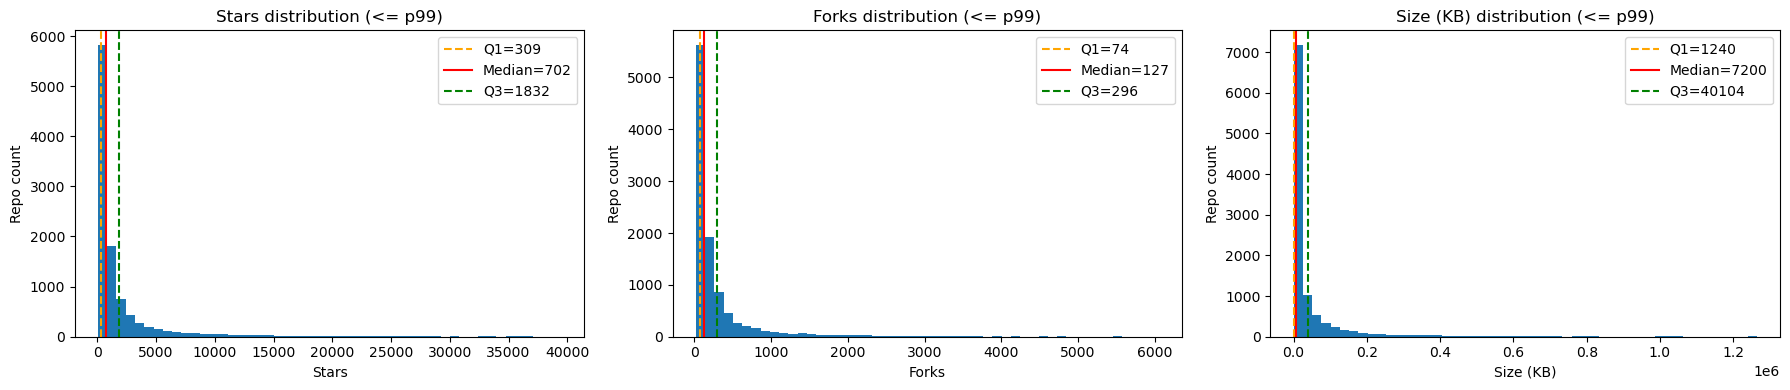

In [13]:

plot_cols = {
    "stargazers_count": "Stars",
    "forks_count": "Forks",
    "size": "Size (KB)",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (col, title) in zip(axes, plot_cols.items()):
    values = df[col].dropna()
    p99 = values.quantile(0.99)
    
    ax.hist(values[values <= p99], bins=50)
    ax.set_title(f"{title} distribution (<= p99)")
    ax.set_xlabel(title)
    ax.set_ylabel("Repo count")
    
    median = values.median()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    
    ax.axvline(q1, color="orange", linestyle="--", label=f"Q1={q1:.0f}")
    ax.axvline(median, color="red", linestyle="-", label=f"Median={median:.0f}")
    ax.axvline(q3, color="green", linestyle="--", label=f"Q3={q3:.0f}")
    ax.legend()

plt.tight_layout()
plt.show()

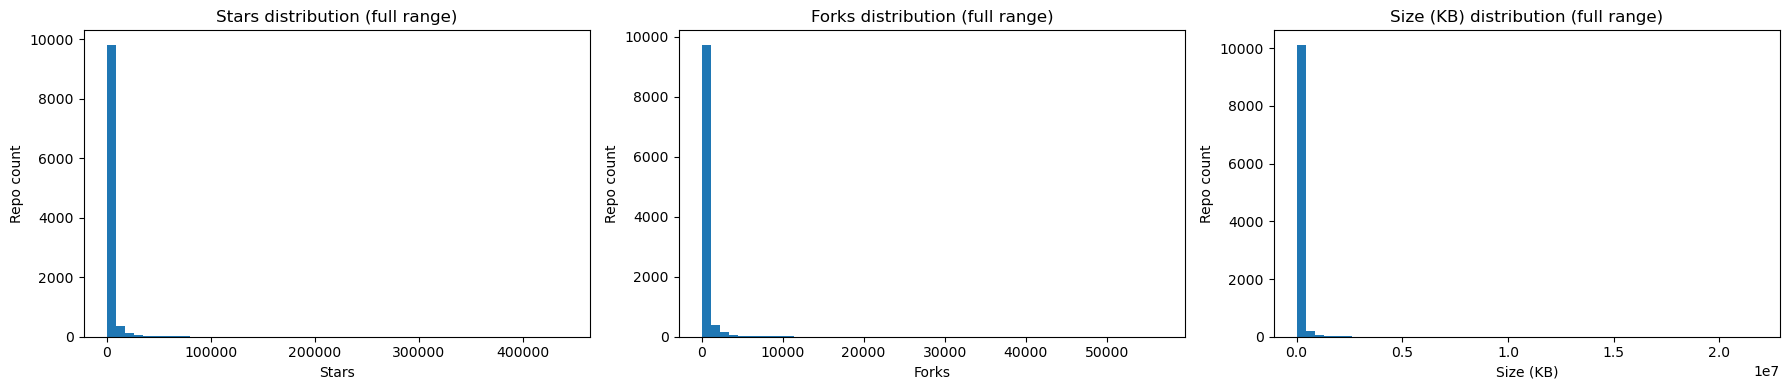

In [15]:
import matplotlib.pyplot as plt

plot_cols = {
    "stargazers_count": "Stars",
    "forks_count": "Forks",
    "size": "Size (KB)",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (col, title) in zip(axes, plot_cols.items()):
    values = df[col].dropna()
    
    ax.hist(values, bins=50)
    ax.set_title(f"{title} distribution (full range)")
    ax.set_xlabel(title)
    ax.set_ylabel("Repo count")

plt.tight_layout()
plt.show()

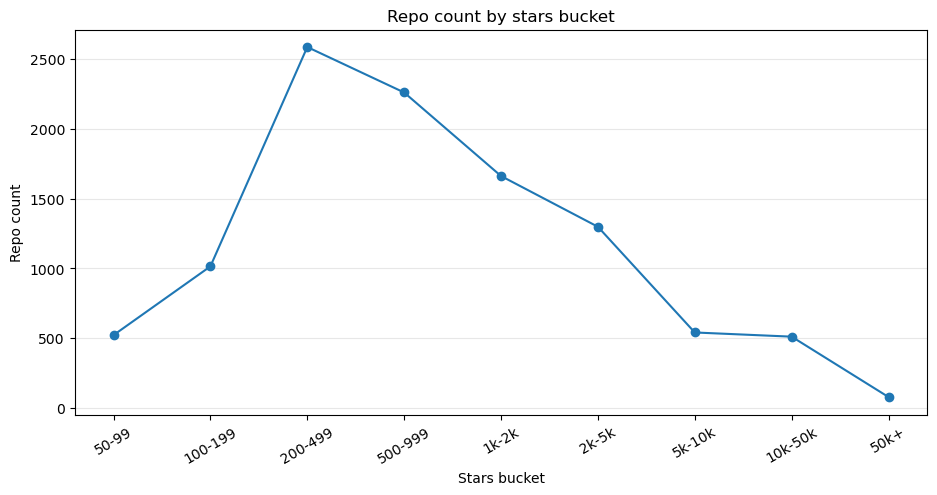

,repo_count
stargazers_count,
50-99,521
100-199,1014
200-499,2587
500-999,2261
1k-2k,1662
2k-5k,1298
5k-10k,540
10k-50k,510
50k+,77


In [17]:

stars = df["stargazers_count"].dropna()

star_bins = [
    50,
    100,
    200,
    500,
    1000,
    2000,
    5000,
    10000,
    50000,
    stars.max() + 1,
]

star_labels = [
    "50-99",
    "100-199",
    "200-499",
    "500-999",
    "1k-2k",
    "2k-5k",
    "5k-10k",
    "10k-50k",
    "50k+",
]

star_bucket = pd.cut(
    stars,
    bins=star_bins,
    labels=star_labels,
    include_lowest=True,
    right=False,
)

star_bucket_counts = star_bucket.value_counts().reindex(star_labels).fillna(0).astype(int)

plt.figure(figsize=(11, 5))
plt.plot(star_bucket_counts.index, star_bucket_counts.values, marker="o")
plt.title("Repo count by stars bucket")
plt.xlabel("Stars bucket")
plt.ylabel("Repo count")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30)
plt.show()

star_bucket_counts.to_frame("repo_count")

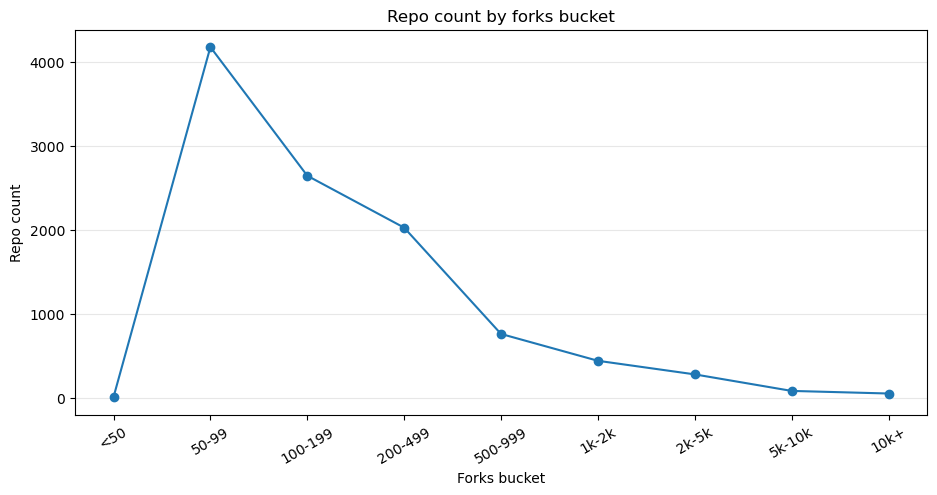

,repo_count
forks_count,
<50,8
50-99,4180
100-199,2646
200-499,2027
500-999,760
1k-2k,440
2k-5k,278
5k-10k,81
10k+,50


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

forks = df["forks_count"].dropna()

fork_bins = [
    0,
    50,
    100,
    200,
    500,
    1000,
    2000,
    5000,
    10000,
    forks.max() + 1,
]

fork_labels = [
    "<50",
    "50-99",
    "100-199",
    "200-499",
    "500-999",
    "1k-2k",
    "2k-5k",
    "5k-10k",
    "10k+",
]

fork_bucket = pd.cut(
    forks,
    bins=fork_bins,
    labels=fork_labels,
    include_lowest=True,
    right=False,
)

fork_bucket_counts = fork_bucket.value_counts().reindex(fork_labels).fillna(0).astype(int)

plt.figure(figsize=(11, 5))
plt.plot(fork_bucket_counts.index, fork_bucket_counts.values, marker="o")
plt.title("Repo count by forks bucket")
plt.xlabel("Forks bucket")
plt.ylabel("Repo count")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30)
plt.show()

fork_bucket_counts.to_frame("repo_count")

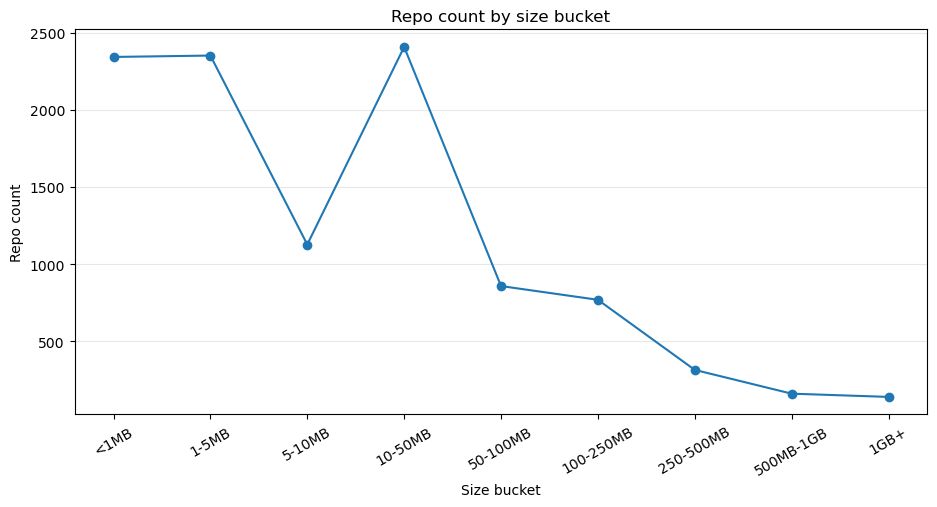

,repo_count
size,
<1MB,2342
1-5MB,2351
5-10MB,1127
10-50MB,2407
50-100MB,858
100-250MB,769
250-500MB,315
500MB-1GB,161
1GB+,140


In [19]:
import pandas as pd
import matplotlib.pyplot as plt

size_mb = df["size"].dropna() / 1024

size_bins = [
    0,
    1,
    5,
    10,
    50,
    100,
    250,
    500,
    1000,
    size_mb.max() + 1,
]

size_labels = [
    "<1MB",
    "1-5MB",
    "5-10MB",
    "10-50MB",
    "50-100MB",
    "100-250MB",
    "250-500MB",
    "500MB-1GB",
    "1GB+",
]

size_bucket = pd.cut(
    size_mb,
    bins=size_bins,
    labels=size_labels,
    include_lowest=True,
    right=False,
)

size_bucket_counts = size_bucket.value_counts().reindex(size_labels).fillna(0).astype(int)

plt.figure(figsize=(11, 5))
plt.plot(size_bucket_counts.index, size_bucket_counts.values, marker="o")
plt.title("Repo count by size bucket")
plt.xlabel("Size bucket")
plt.ylabel("Repo count")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=30)
plt.show()

size_bucket_counts.to_frame("repo_count")

In [20]:
import pandas as pd
import re

def is_missing_value(x):
    if x is None:
        return True
    if isinstance(x, float) and pd.isna(x):
        return True
    if isinstance(x, str) and x.strip() == "":
        return True
    if isinstance(x, (list, dict)) and len(x) == 0:
        return True
    return False

def non_ascii_ratio(text):
    if not isinstance(text, str) or text.strip() == "":
        return 0
    chars = [c for c in text if not c.isspace()]
    if not chars:
        return 0
    non_ascii = sum(1 for c in chars if ord(c) > 127)
    return non_ascii / len(chars)

df_eda = df.copy()

df_eda["missing_description"] = df_eda["description"].apply(is_missing_value)
df_eda["missing_topics"] = df_eda["topics"].apply(is_missing_value)
df_eda["missing_license"] = df_eda["license"].apply(is_missing_value)
df_eda["missing_language"] = df_eda["language"].apply(is_missing_value)
df_eda["missing_homepage"] = df_eda["homepage"].apply(is_missing_value)

df_eda["description_non_ascii_ratio"] = df_eda["description"].apply(non_ascii_ratio)
df_eda["description_has_non_ascii"] = df_eda["description_non_ascii_ratio"] > 0
df_eda["description_likely_non_english"] = df_eda["description_non_ascii_ratio"] >= 0.2

missing_overview = pd.DataFrame({
    "metric": [
        "total_repos",
        "missing_description",
        "missing_topics",
        "missing_license",
        "missing_language",
        "missing_homepage",
        "description_has_non_ascii",
        "description_likely_non_english",
    ],
    "count": [
        len(df_eda),
        df_eda["missing_description"].sum(),
        df_eda["missing_topics"].sum(),
        df_eda["missing_license"].sum(),
        df_eda["missing_language"].sum(),
        df_eda["missing_homepage"].sum(),
        df_eda["description_has_non_ascii"].sum(),
        df_eda["description_likely_non_english"].sum(),
    ],
})

missing_overview["rate"] = missing_overview["count"] / len(df_eda)

missing_overview

,metric,count,rate
0,total_repos,10470,1.000000
1,missing_description,491,0.046896
2,missing_topics,3514,0.335626
3,missing_license,1101,0.105158
4,missing_language,8,0.000764
5,missing_homepage,5103,0.487393
6,description_has_non_ascii,1661,0.158644
7,description_likely_non_english,750,0.071633


In [21]:
count_summary = {
    "total_repos": len(df_eda),
    "language_python": (df_eda["language"] == "Python").sum(),
    "public_repos": (df_eda["visibility"] == "public").sum(),
    "archived_true": (df_eda["archived"] == True).sum(),
    "disabled_true": (df_eda["disabled"] == True).sum(),
    "fork_true": (df_eda["fork"] == True).sum(),
    "template_true": (df_eda["is_template"] == True).sum(),
    "size_lt_100kb": (df_eda["size"] < 100).sum(),
    "size_gt_250mb": (df_eda["size"] > 250 * 1024).sum(),
    "size_gt_1gb": (df_eda["size"] > 1024 * 1024).sum(),
    "stars_50_2000": ((df_eda["stargazers_count"] >= 50) & (df_eda["stargazers_count"] <= 2000)).sum(),
    "forks_50_1000": ((df_eda["forks_count"] >= 50) & (df_eda["forks_count"] <= 1000)).sum(),
}

count_summary_df = pd.DataFrame.from_dict(
    count_summary,
    orient="index",
    columns=["count"]
)

count_summary_df["rate"] = count_summary_df["count"] / len(df_eda)

count_summary_df

,count,rate
total_repos,10470,1.000000
language_python,10462,0.999236
public_repos,10470,1.000000
archived_true,0,0.000000
disabled_true,0,0.000000
fork_true,0,0.000000
template_true,90,0.008596
size_lt_100kb,368,0.035148
size_gt_250mb,616,0.058835
size_gt_1gb,130,0.012416
